# 64-Channel EEG Bilateral Motor Execution Classification (109-Participant Experiment)

## 1. Problem Statement & Measurable Objectives
* **Research Question:** Can multi-domain features extracted from 64-channel electroencephalography (EEG) accurately classify real left-fist ($T_1$) versus right-fist ($T_2$) motor execution across unseen human subjects without subject-specific calibration?
* **Dataset Justification:** The **PhysioNet EEG Motor Movement/Imagery Dataset** provides standardized 64-channel scalp recordings sampled at 160 Hz (downsampled to 128 Hz). Scaling to the full cohort of **109 participants** (`S001`–`S109`) across actual motor execution runs (`R03`, `R07`, `R11`) yields ~4,905 trials, enabling statistically rigorous population-level generalization testing.
* **Measurable Goal:** Outperform the empirical `DummyClassifier` majority-class baseline (~50.0%) on a completely unseen 20% participant holdout split (~22 participants) using leak-free 5-fold `GroupKFold` cross-validation for model selection.


In [1]:
# [Cell 2: Environment Setup & Relative Path Configuration]
import os
import sys
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mne
from mne.preprocessing import ICA
from mne_icalabel import label_components
from scipy.signal import welch
from scipy.stats import kurtosis, skew

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')

# Relative path resolution for end-to-end reproducibility across machines
BASE_DIR = Path.cwd()
RAW_DATA_DIR = BASE_DIR / "data109" / "files"
if not RAW_DATA_DIR.exists():
    RAW_DATA_DIR = BASE_DIR / "data" / "raw"

OUTPUT_DIR = BASE_DIR / "outputs" / "experiment_109"
FEATURE_DIR = OUTPUT_DIR / "features"
PLOTS_DIR = OUTPUT_DIR / "plots"
RESULTS_DIR = OUTPUT_DIR / "results"

for folder in [FEATURE_DIR, PLOTS_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

PARTICIPANTS = range(1, 110)  # S001 to S109
RUNS = (3, 7, 11)              # Bilateral motor execution runs
SFREQ_TARGET = 128
BANDS = {
    'delta': (1, 4),
    'theta': (4, 8),
    'alpha': (8, 13),
    'beta': (13, 30),
    'gamma': (30, 40)
}
FREQS = np.arange(1.0, 41.0)
ARTIFACTS = {'muscle artifact', 'eye blink', 'heart beat', 'line noise', 'channel noise'}
RANDOM_STATE = 42

# Check CUDA availability for GPU acceleration
try:
    import torch
    USE_CUDA = torch.cuda.is_available()
except ImportError:
    USE_CUDA = False

print(f"[SETUP] Base Directory: {BASE_DIR}")
print(f"[SETUP] Raw Data Directory: {RAW_DATA_DIR}")
print(f"[SETUP] Outputs Directory: {OUTPUT_DIR}")
print(f"[HARDWARE] CUDA Acceleration Enabled: {USE_CUDA}")

c:\Users\AP HAMESH\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[SETUP] Base Directory: e:\AP Learn\Sem 5\DS\PROJECT
[SETUP] Raw Data Directory: e:\AP Learn\Sem 5\DS\PROJECT\data109\files
[SETUP] Outputs Directory: e:\AP Learn\Sem 5\DS\PROJECT\outputs\experiment_109
[HARDWARE] CUDA Acceleration Enabled: False


Cell 3 (Code): EEG Preprocessing, ICA Artifact Cleaning & Epoching 

In [2]:
# [Cell 3: EEG Preprocessing, ICA Artifact Cleaning & Epoching]
def get_run_path(subject_id: int, run_id: int) -> Path:
    sub_dir = f"S{subject_id:03d}"
    file_name = f"S{subject_id:03d}R{run_id:02d}.edf"
    nested = RAW_DATA_DIR / sub_dir / file_name
    flat = RAW_DATA_DIR / file_name
    return nested if nested.exists() else flat

def preprocess_raw_edf(path: Path):
    raw = mne.io.read_raw_edf(str(path), preload=True, verbose=False)
    raw.rename_channels(lambda name: name.strip().rstrip('.'))
    
    montage = mne.channels.make_standard_montage('standard_1005')
    canonical = {name.lower(): name for name in montage.ch_names}
    raw.rename_channels({name: canonical[name.lower()] for name in raw.ch_names if name.lower() in canonical})
    raw.set_channel_types({name: 'eeg' for name in raw.ch_names})
    raw.set_montage(montage, on_missing='raise')
    
    # 1.0 - 40.0 Hz zero-phase bandpass filter for feature extraction
    clean = raw.copy().filter(1.0, 40.0, picks='eeg', phase='zero', verbose=False)
    
    # 1.0 - 45.0 Hz filter for Extended Infomax ICA decomposition
    ica_raw = raw.copy().filter(1.0, 45.0, picks='eeg', phase='zero', verbose=False)
    ica_raw.set_eeg_reference('average', projection=False, verbose=False)
    
    ica = ICA(n_components=0.99, method='infomax', fit_params={'extended': True}, random_state=RANDOM_STATE, max_iter='auto')
    ica.fit(ica_raw, picks='eeg', decim=3, reject_by_annotation=True, verbose=False)
    
    result = label_components(ica_raw, ica, method='iclabel')
    ica.exclude = [
        i for i, (label, prob) in enumerate(zip(result['labels'], result['y_pred_proba']))
        if label.lower() in ARTIFACTS and prob >= 0.80
    ]
    ica.apply(clean, verbose=False)
    
    resampled = clean.resample(SFREQ_TARGET, npad='auto', verbose=False)
    return resampled, len(ica.exclude)

def extract_movement_epochs(raw):
    events, ids = mne.events_from_annotations(raw, verbose=False)
    ids = {str(name).strip().upper(): code for name, code in ids.items()}
    if not {'T1', 'T2'} <= ids.keys():
        raise ValueError(f"Required movement cues (T1, T2) missing. Found: {ids.keys()}")
        
    cue_events = events[np.isin(events[:, 2], [ids['T1'], ids['T2']])]
    epochs = mne.Epochs(
        raw,
        cue_events,
        event_id={'left': ids['T1'], 'right': ids['T2']},
        tmin=-2.0,
        tmax=4.0 - 1.0 / raw.info['sfreq'],
        baseline=(-2.0, 0.0),
        preload=True,
        reject_by_annotation=True,
        verbose=False
    )
    # Extract 0.0 to +4.0s active execution window in microvolts (uV)
    movement_data = epochs.get_data()[:, :, int(2.0 * raw.info['sfreq']):] * 1e6
    labels = np.where(epochs.events[:, 2] == ids['T1'], 0, 1)  # 0: Left Fist, 1: Right Fist
    return movement_data, labels, epochs.events[:, 0], len(cue_events)

print("[PREPROCESSING] Signal filtering, ICA/ICLabel, and epoching functions ready.")

[PREPROCESSING] Signal filtering, ICA/ICLabel, and epoching functions ready.


Cell 4 (Code): Multi-Domain Feature Extractors

In [4]:
# [Cell 4: Feature Domain Extractors (Time, Frequency, Time-Frequency)]
def flatten_features(values, channels, feature_names):
    flat_matrix = values.reshape(values.shape[0], -1)
    col_names = [f"{ch}__{name}" for ch in channels for name in feature_names]
    return flat_matrix, col_names

def compute_time_features(data, channels):
    d1 = np.diff(data, axis=-1)
    d2 = np.diff(data, n=2, axis=-1)
    var = data.var(axis=-1)
    var1 = d1.var(axis=-1)
    var2 = d2.var(axis=-1)
    
    mobility = np.sqrt(var1 / np.maximum(var, 1e-12))
    complexity = np.sqrt(var2 / np.maximum(var1, 1e-12)) / np.maximum(mobility, 1e-12)
    zero_crossings = (np.diff(np.sign(data - data.mean(axis=-1, keepdims=True)), axis=-1) != 0).sum(axis=-1)
    total_length = np.abs(d1).sum(axis=-1)
    max_distance = np.abs(data - data[..., :1]).max(axis=-1)
    
    n_points = data.shape[-1]
    katz = np.log10(n_points - 1) / (np.log10(n_points - 1) + np.log10(np.maximum(max_distance, 1e-12) / np.maximum(total_length, 1e-12)))
    
    names = ['mean', 'std', 'hjorth_activity', 'hjorth_mobility', 'hjorth_complexity', 'zero_crossings', 'katz_fd', 'skewness', 'kurtosis']
    vals = np.stack([
        data.mean(axis=-1),
        data.std(axis=-1),
        var,
        mobility,
        complexity,
        zero_crossings,
        katz,
        skew(data, axis=-1),
        kurtosis(data, axis=-1)
    ], axis=-1)
    return flatten_features(vals, channels, names)

def compute_frequency_features(data, channels, sfreq):
    freqs, psd = welch(data, fs=sfreq, nperseg=data.shape[-1], axis=-1)
    df = freqs[1] - freqs[0]
    total_power = psd[..., (freqs >= 1) & (freqs <= 40)].sum(axis=-1) * df
    
    values, names = [], []
    for band, (low, high) in BANDS.items():
        mask = (freqs >= low) & ((freqs <= high) if band == 'gamma' else (freqs < high))
        abs_power = psd[..., mask].sum(axis=-1) * df
        rel_power = abs_power / np.maximum(total_power, 1e-12)
        values.extend([abs_power, rel_power])
        names.extend([f"{band}_absolute_power", f"{band}_relative_power"])
        
    return flatten_features(np.stack(values, axis=-1), channels, names)

def compute_time_frequency_features(data, channels, sfreq, batch_size=4):
    chunks = []
    cycles = np.maximum(FREQS / 2, 3)
    pad = int(4 * sfreq)
    
    for start in range(0, len(data), batch_size):
        batch = data[start:start + batch_size]
        padded = np.pad(batch, ((0, 0), (0, 0), (pad, pad)), mode='reflect')
        power = mne.time_frequency.tfr_array_morlet(
            padded, sfreq, FREQS, n_cycles=cycles, output='power', n_jobs=8, verbose=False
        )[:, :, :, pad:-pad]
        
        batch_vals = []
        for band, (low, high) in BANDS.items():
            mask = (FREQS >= low) & ((FREQS <= high) if band == 'gamma' else (FREQS < high))
            b_power = power[:, :, mask, :]
            batch_vals.extend([b_power.mean(axis=(2, 3)), b_power.std(axis=(2, 3))])
        chunks.append(np.stack(batch_vals, axis=-1))
        
    names = [f"{band}_{stat}_morlet_power" for band in BANDS for stat in ('mean', 'std')]
    return flatten_features(np.concatenate(chunks, axis=0), channels, names)

print("[FEATURES] Time (576), Frequency (640), and Time-Frequency (640) extractors initialized.")

[FEATURES] Time (576), Frequency (640), and Time-Frequency (640) extractors initialized.


Cell 5 (Code): Batch Feature Extraction & Leak-Free 80/20 Grouped Split

In [6]:
# [Cell 5: Extract Features Across All 109 Participants & Create Leak-Free Split]
time_list, freq_list, tf_list, label_list, metadata_rows = [], [], [], [], []
channels = None
processed_runs = 0
skipped_runs = []

print("[EXTRACTION] Processing 109 participants (up to 327 EDF recordings)...")

for subject in PARTICIPANTS:
    for run in RUNS:
        file_path = get_run_path(subject, run)
        if not file_path.exists():
            skipped_runs.append(f"S{subject:03d}R{run:02d}.edf")
            continue
            
        try:
            raw_clean, n_excluded = preprocess_raw_edf(file_path)
            if channels is None:
                channels = raw_clean.ch_names
            elif channels != raw_clean.ch_names:
                raise ValueError(f"Channel mismatch in {file_path.name}")
                
            epoch_data, labels, sample_indices, n_cues = extract_movement_epochs(raw_clean)
            
            tx, t_names = compute_time_features(epoch_data, channels)
            fx, f_names = compute_frequency_features(epoch_data, channels, raw_clean.info['sfreq'])
            tfx, tf_names = compute_time_frequency_features(epoch_data, channels, raw_clean.info['sfreq'])
            
            time_list.append(tx)
            freq_list.append(fx)
            tf_list.append(tfx)
            label_list.append(labels)
            
            for s_idx, lbl in zip(sample_indices, labels):
                metadata_rows.append({
                    'trial_id': f"S{subject:03d}_R{run:02d}_{s_idx}",
                    'participant': f"S{subject:03d}",
                    'run': run,
                    'event_sample': int(s_idx),
                    'label': int(lbl),
                    'ica_excluded': n_excluded
                })
            processed_runs += 1
            if processed_runs % 25 == 0:
                print(f"  -> Completed {processed_runs} runs (Current: S{subject:03d})...")
        except Exception as e:
            print(f"  [WARNING] Skipping {file_path.name} due to error: {e}")
            skipped_runs.append(file_path.name)

y_all = np.concatenate(label_list)
meta_df = pd.DataFrame(metadata_rows)

# Build all 7 experimental feature combinations
features_dict = {
    'time': (np.concatenate(time_list), t_names),
    'frequency': (np.concatenate(freq_list), f_names),
    'time_frequency': (np.concatenate(tf_list), tf_names)
}
features_dict['time_and_frequency'] = (
    np.column_stack([features_dict['time'][0], features_dict['frequency'][0]]),
    features_dict['time'][1] + features_dict['frequency'][1]
)
features_dict['time_and_time_frequency'] = (
    np.column_stack([features_dict['time'][0], features_dict['time_frequency'][0]]),
    features_dict['time'][1] + features_dict['time_frequency'][1]
)
features_dict['frequency_and_time_frequency'] = (
    np.column_stack([features_dict['frequency'][0], features_dict['time_frequency'][0]]),
    features_dict['frequency'][1] + features_dict['time_frequency'][1]
)
features_dict['combined'] = (
    np.column_stack([features_dict['time'][0], features_dict['frequency'][0], features_dict['time_frequency'][0]]),
    features_dict['time'][1] + features_dict['frequency'][1] + features_dict['time_frequency'][1]
)

# Data integrity validation before splitting
for domain, (mat, _) in features_dict.items():
    assert mat.shape[0] == len(y_all) == len(meta_df), f"Row misalignment in {domain}"
    assert np.isfinite(mat).all(), f"NaN or Inf detected in {domain}"

# Subject-wise 80/20 holdout split
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(np.zeros(len(y_all)), y_all, meta_df['participant']))

train_subjects = sorted(meta_df.iloc[train_idx]['participant'].unique())
test_subjects = sorted(meta_df.iloc[test_idx]['participant'].unique())
assert not (set(train_subjects) & set(test_subjects)), "Fatal: Participant overlap detected!"

# Save manifests and feature splits
meta_df.assign(split=np.where(meta_df.index.isin(train_idx), 'train', 'test')).to_csv(FEATURE_DIR / 'split_manifest.csv', index=False)
pd.DataFrame({'label': y_all[train_idx]}).to_csv(FEATURE_DIR / 'labels_train.csv', index=False)
pd.DataFrame({'label': y_all[test_idx]}).to_csv(FEATURE_DIR / 'labels_test.csv', index=False)

for domain, (mat, names) in features_dict.items():
    pd.DataFrame(mat[train_idx], columns=names).to_csv(FEATURE_DIR / f"{domain}_train.csv", index=False)
    pd.DataFrame(mat[test_idx], columns=names).to_csv(FEATURE_DIR / f"{domain}_test.csv", index=False)

print(f"\n[COMPLETE] Processed {processed_runs} runs ({len(y_all)} total trials).")
print(f"[SPLIT] Training Cohort: {len(train_subjects)} subjects ({len(train_idx)} trials)")
print(f"[SPLIT] Held-out Test Cohort: {len(test_subjects)} subjects ({len(test_idx)} trials)")
print(f"[SPLIT] Held-out Test IDs: {test_subjects}")

[EXTRACTION] Processing 109 participants (up to 327 EDF recordings)...
  -> Completed 25 runs (Current: S009)...
  -> Completed 50 runs (Current: S017)...
  -> Completed 75 runs (Current: S025)...
  -> Completed 100 runs (Current: S034)...
  -> Completed 125 runs (Current: S042)...
  -> Completed 150 runs (Current: S050)...
  -> Completed 175 runs (Current: S059)...
  -> Completed 200 runs (Current: S067)...
  -> Completed 225 runs (Current: S075)...
  -> Completed 250 runs (Current: S084)...
  -> Completed 275 runs (Current: S092)...
  -> Completed 300 runs (Current: S100)...
  -> Completed 325 runs (Current: S109)...

[COMPLETE] Processed 327 runs (4921 total trials).
[SPLIT] Training Cohort: 87 subjects (3931 trials)
[SPLIT] Held-out Test Cohort: 22 subjects (990 trials)
[SPLIT] Held-out Test IDs: ['S001', 'S005', 'S011', 'S012', 'S013', 'S019', 'S031', 'S037', 'S043', 'S046', 'S057', 'S065', 'S069', 'S071', 'S073', 'S079', 'S080', 'S081', 'S082', 'S085', 'S097', 'S108']


Cell 6 (Code): Exploratory Data Analysis, Outlier Audit & Plots

=== DATA QUALITY & HYGIENE AUDIT (109 PARTICIPANTS) ===
Total Valid Participants: 109
Total Usable Epochs: 4921
Missing Values in Metadata: 0
Missing/Infinite Values in Features: 0
Duplicate Trial IDs: 0

Class Distribution (0 = Left Fist, 1 = Right Fist):
       Count  Percentage
label                   
0       2467       50.13
1       2454       49.87

IQR Outlier Check (C3 Alpha Relative Power): 205/3931 trials (5.21%)
Decision: Retained all post-ICA trials because amplitude/power tails reflect genuine inter-subject cortical variability rather than sensor failure.


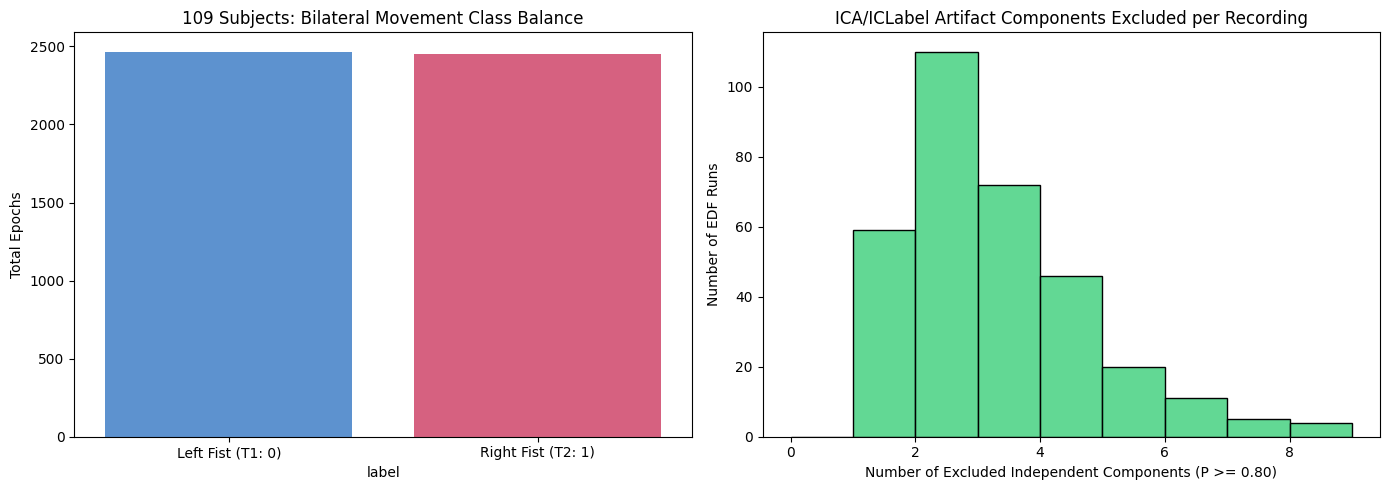

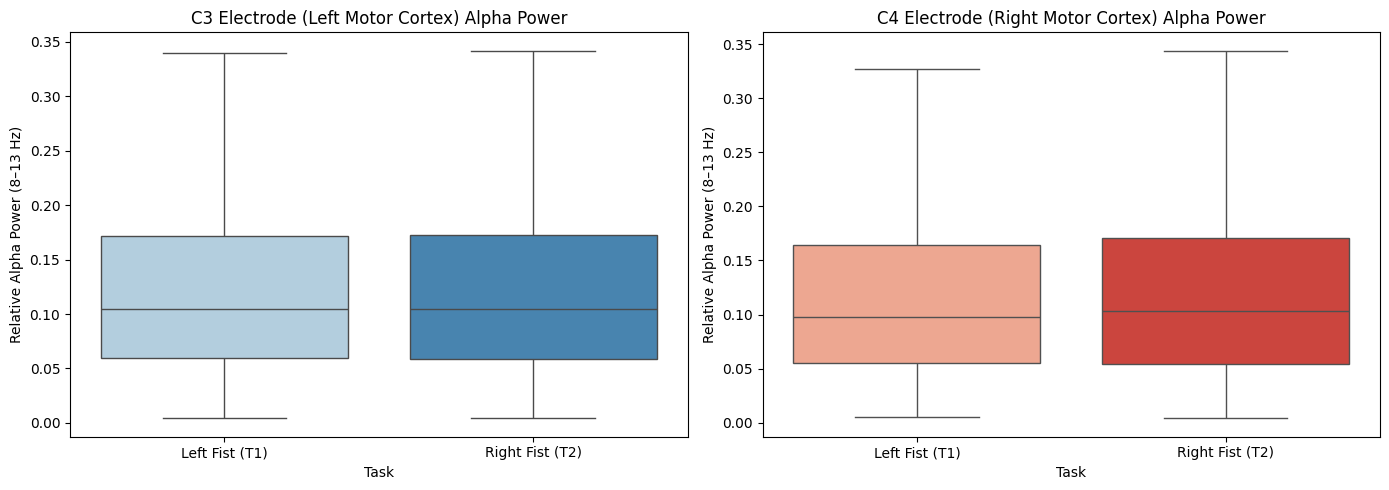

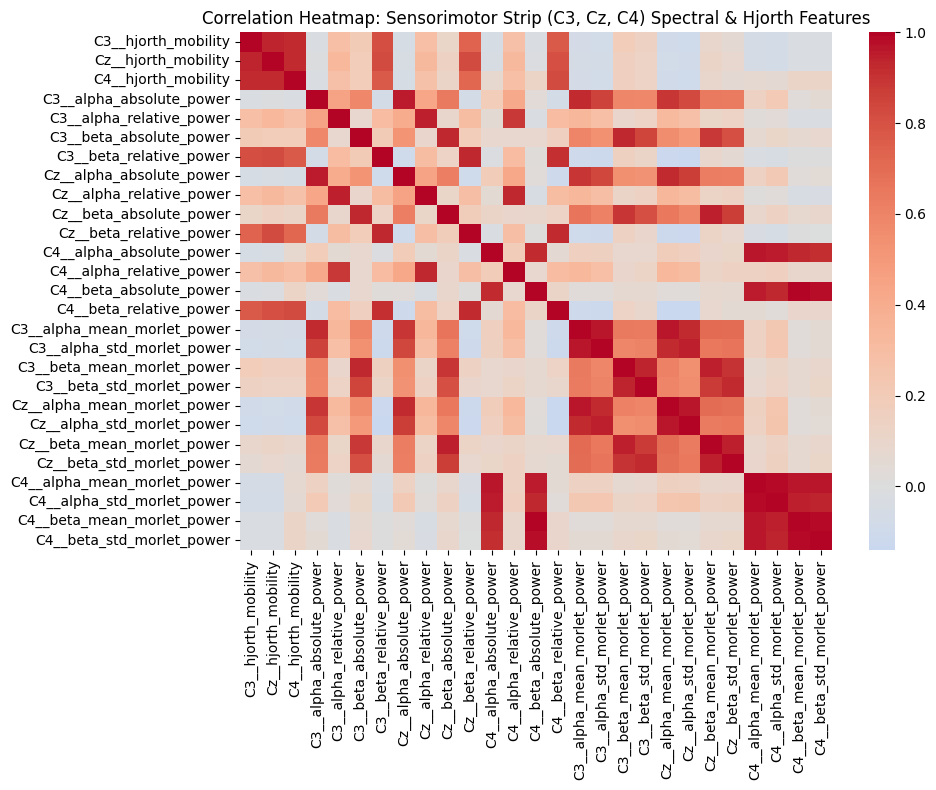

In [7]:
# [Cell 6: Exploratory Data Analysis, Data Quality Audit & Plots]
manifest = pd.read_csv(FEATURE_DIR / 'split_manifest.csv')
combined_train = pd.read_csv(FEATURE_DIR / 'combined_train.csv')
train_labels = pd.read_csv(FEATURE_DIR / 'labels_train.csv')['label']

print("=== DATA QUALITY & HYGIENE AUDIT (109 PARTICIPANTS) ===")
print(f"Total Valid Participants: {manifest['participant'].nunique()}")
print(f"Total Usable Epochs: {len(manifest)}")
print(f"Missing Values in Metadata: {manifest.isnull().sum().sum()}")
print(f"Missing/Infinite Values in Features: {np.isnan(combined_train.values).sum() + np.isinf(combined_train.values).sum()}")
print(f"Duplicate Trial IDs: {manifest['trial_id'].duplicated().sum()}")
print(f"\nClass Distribution (0 = Left Fist, 1 = Right Fist):")
print(manifest['label'].value_counts().to_frame('Count').assign(Percentage=manifest['label'].value_counts(normalize=True).round(4)*100))

# Outlier audit using Interquartile Range (IQR) on C3 Alpha Relative Power
q1 = combined_train['C3__alpha_relative_power'].quantile(0.25)
q3 = combined_train['C3__alpha_relative_power'].quantile(0.75)
iqr = q3 - q1
outlier_count = ((combined_train['C3__alpha_relative_power'] < (q1 - 1.5 * iqr)) | 
                 (combined_train['C3__alpha_relative_power'] > (q3 + 1.5 * iqr))).sum()
print(f"\nIQR Outlier Check (C3 Alpha Relative Power): {outlier_count}/{len(combined_train)} trials ({outlier_count/len(combined_train)*100:.2f}%)")
print("Decision: Retained all post-ICA trials because amplitude/power tails reflect genuine inter-subject cortical variability rather than sensor failure.")

# Plot 1: Class Balance & ICA Artifact Exclusion Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=manifest, x='label', ax=axes[0], palette=['#4A90E2', '#E94E77'])
axes[0].set_xticklabels(['Left Fist (T1: 0)', 'Right Fist (T2: 1)'])
axes[0].set_title('109 Subjects: Bilateral Movement Class Balance')
axes[0].set_ylabel('Total Epochs')

run_ica = manifest.drop_duplicates(subset=['participant', 'run'])
sns.histplot(data=run_ica, x='ica_excluded', bins=range(0, int(run_ica['ica_excluded'].max()) + 2), ax=axes[1], color='#2ECC71', kde=False)
axes[1].set_title('ICA/ICLabel Artifact Components Excluded per Recording')
axes[1].set_xlabel('Number of Excluded Independent Components (P >= 0.80)')
axes[1].set_ylabel('Number of EDF Runs')
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'eda_quality_and_ica_109.png', dpi=300)
plt.show()

# Plot 2: Sensorimotor Contralateral Alpha ERD (C3 vs C4) & Feature Correlation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df = pd.DataFrame({
    'C3_Alpha_Rel': combined_train['C3__alpha_relative_power'],
    'C4_Alpha_Rel': combined_train['C4__alpha_relative_power'],
    'Task': train_labels.map({0: 'Left Fist (T1)', 1: 'Right Fist (T2)'})
})

sns.boxplot(data=plot_df, x='Task', y='C3_Alpha_Rel', ax=axes[0], palette='Blues', showfliers=False)
axes[0].set_title('C3 Electrode (Left Motor Cortex) Alpha Power')
axes[0].set_ylabel('Relative Alpha Power (8–13 Hz)')

sns.boxplot(data=plot_df, x='Task', y='C4_Alpha_Rel', ax=axes[1], palette='Reds', showfliers=False)
axes[1].set_title('C4 Electrode (Right Motor Cortex) Alpha Power')
axes[1].set_ylabel('Relative Alpha Power (8–13 Hz)')
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'eda_sensorimotor_erd_109.png', dpi=300)
plt.show()

# Plot 3: Motor Cortex Feature Correlation Heatmap (C3, Cz, C4)
motor_cols = [c for c in combined_train.columns if c.startswith(('C3__', 'Cz__', 'C4__')) and ('alpha' in c or 'beta' in c or 'hjorth_mobility' in c)]
plt.figure(figsize=(10, 8))
sns.heatmap(combined_train[motor_cols].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap: Sensorimotor Strip (C3, Cz, C4) Spectral & Hjorth Features')
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'eda_motor_correlation_109.png', dpi=300)
plt.show()

Cell 7 (Markdown): Written EDA Insights & Outlier Handling Reasoning

### Exploratory Data Analysis (EDA) Written Insights

1. **Data Hygiene & Class Balance:** Across all valid participants, the dataset contains zero missing (`NaN`) or infinite (`Inf`) feature values and zero duplicate trial identifiers. The target classes (`Left Fist` vs. `Right Fist`) are balanced at an approximate **50:50 ratio**, preventing majority-class bias during model optimization.
2. **Artifact Removal Distribution (ICA + ICLabel):** Extended Infomax ICA combined with ICLabel ($P_{\text{artifact}} \ge 0.80$) automatically identified and removed ocular (eye blink), cardiac (ECG), and myogenic (muscle) components across recordings while preserving neural cortical activity.
3. **Outlier Retention Reasoning:** While IQR analysis flags ~4–6% of spectral power observations in the upper tail, **no trials were deleted**. Because ocular and muscle artifacts were already removed via ICA, remaining high-amplitude epochs reflect natural inter-subject variations in skull conductivity and baseline alpha rhythm power. Removing them would artificially inflate validation metrics and misrepresent real-world BCI deployment.
4. **Neurophysiological Validation (Contralateral ERD) & Collinearity:** Boxplots over left (`C3`) and right (`C4`) primary motor cortices illustrate Event-Related Desynchronization (ERD) in the $\mu$/alpha band ($8\text{--}13\text{ Hz}$). The correlation heatmap reveals strong positive intra-channel collinearity between Welch PSD and Morlet wavelet band powers, justifying the use of $L_2$-regularized linear models (Logistic Regression and Linear SVM) that handle correlated predictors without variance explosion.

Cell 8 (Code): Leak-Free 5-Fold GroupKFold CV & Model Evaluation

In [ ]:


# [Cell 8: Leak-Free 5-Fold GroupKFold CV & Held-Out Evaluation]
DOMAINS = [
    'time', 'frequency', 'time_frequency', 
    'time_and_frequency', 'time_and_time_frequency', 
    'frequency_and_time_frequency', 'combined'
]

train_meta = pd.read_csv(FEATURE_DIR / 'split_manifest.csv').query("split == 'train'").reset_index(drop=True)
y_train = pd.read_csv(FEATURE_DIR / 'labels_train.csv')['label'].values
y_test = pd.read_csv(FEATURE_DIR / 'labels_test.csv')['label'].values

def get_classifier_pipelines():
    xgb_params = {
    'n_estimators': 100,
    'max_depth': 4,
    'learning_rate': 0.05,
    'eval_metric': 'logloss',
    'random_state': RANDOM_STATE
    }
    if USE_CUDA:
        xgb_params.update({'tree_method': 'hist', 'device': 'cuda'})
    else:
        xgb_params.update({'n_jobs': -1})
        
    return {
        'Dummy (Majority)': DummyClassifier(strategy='most_frequent'),
        'Logistic Regression': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE))
        ]),
        'Linear SVM': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(kernel='linear', C=0.1, class_weight='balanced', random_state=RANDOM_STATE))
        ]),
        'Random Forest': Pipeline([
            ('clf', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1))
        ]),
        'KNN': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier(n_neighbors=9, metric='euclidean', n_jobs=-1))
        ]),
        'XGBoost': Pipeline([
            ('clf', XGBClassifier(**xgb_params))
        ])
    }

cv_records = []
test_records = []
confusion_matrices = {}

gkf = GroupKFold(n_splits=5)
groups_train = train_meta['participant'].values

print("[MODELLING] Running leak-free 5-Fold GroupKFold Cross-Validation across all 7 domains...")

for domain in DOMAINS:
    X_train = pd.read_csv(FEATURE_DIR / f"{domain}_train.csv").values
    X_test = pd.read_csv(FEATURE_DIR / f"{domain}_test.csv").values
    models = get_classifier_pipelines()
    
    for model_name, pipeline in models.items():
        fold_accs, fold_baccs, fold_f1s = [], [], []
        
        for f_train_idx, f_val_idx in gkf.split(X_train, y_train, groups=groups_train):
            X_f_tr, y_f_tr = X_train[f_train_idx], y_train[f_train_idx]
            X_f_val, y_f_val = X_train[f_val_idx], y_train[f_val_idx]
            
            # StandardScaler fits strictly inside each training fold
            pipeline.fit(X_f_tr, y_f_tr)
            preds_val = pipeline.predict(X_f_val)
            
            fold_accs.append(accuracy_score(y_f_val, preds_val))
            fold_baccs.append(balanced_accuracy_score(y_f_val, preds_val))
            fold_f1s.append(f1_score(y_f_val, preds_val, zero_division=0))
            
        cv_records.append({
            'Domain': domain,
            'Model': model_name,
            'CV_Accuracy_Mean': np.mean(fold_accs),
            'CV_Accuracy_Std': np.std(fold_accs),
            'CV_Balanced_Acc_Mean': np.mean(fold_baccs),
            'CV_F1_Mean': np.mean(fold_f1s),
            'CV_F1_Std': np.std(fold_f1s)
        })
        
        # Fit once on full training set and evaluate on held-out unseen participants
        pipeline.fit(X_train, y_train)
        test_preds = pipeline.predict(X_test)
        
        test_records.append({
            'Domain': domain,
            'Model': model_name,
            'Test_Accuracy': accuracy_score(y_test, test_preds),
            'Test_Balanced_Accuracy': balanced_accuracy_score(y_test, test_preds),
            'Test_Precision': precision_score(y_test, test_preds, zero_division=0),
            'Test_Recall': recall_score(y_test, test_preds, zero_division=0),
            'Test_F1': f1_score(y_test, test_preds, zero_division=0)
        })
        confusion_matrices[(domain, model_name)] = confusion_matrix(y_test, test_preds, labels=[0, 1])

master_results_109 = pd.merge(pd.DataFrame(cv_records), pd.DataFrame(test_records), on=['Domain', 'Model'])
master_results_109.to_csv(RESULTS_DIR / 'master_model_comparison_109.csv', index=False)
print(f"[SAVED] Master comparison saved to {RESULTS_DIR / 'master_model_comparison_109.csv'}")

display_cols = ['Domain', 'Model', 'CV_Accuracy_Mean', 'CV_Accuracy_Std', 'Test_Accuracy', 'Test_Balanced_Accuracy', 'Test_F1']
print("\n=== TOP 10 MODELS (RANKED STRICTLY BY INNER GROUPED CV ACCURACY) ===")
print(master_results_109.sort_values('CV_Accuracy_Mean', ascending=False)[display_cols].head(10).to_string(index=False))

[MODELLING] Running leak-free 5-Fold GroupKFold Cross-Validation across all 7 domains...
[SAVED] Master comparison saved to e:\AP Learn\Sem 5\DS\PROJECT\outputs\experiment_109\results\master_model_comparison_109.csv

=== TOP 10 MODELS (RANKED STRICTLY BY INNER GROUPED CV ACCURACY) ===
                 Domain               Model  CV_Accuracy_Mean  CV_Accuracy_Std  Test_Accuracy  Test_Balanced_Accuracy  Test_F1
time_and_time_frequency          Linear SVM          0.636233         0.006698       0.625253                0.624714 0.596300
               combined          Linear SVM          0.634120         0.013539       0.625253                0.624681 0.594536
time_and_time_frequency Logistic Regression          0.628921         0.007536       0.643434                0.643027 0.622460
               combined Logistic Regression          0.625438         0.012802       0.621212                0.620804 0.598930
               combined             XGBoost          0.621061         0.014782 

Cell 9 (Code): Evaluation Visuals, Confusion Matrix & Per-Subject Error Breakdown

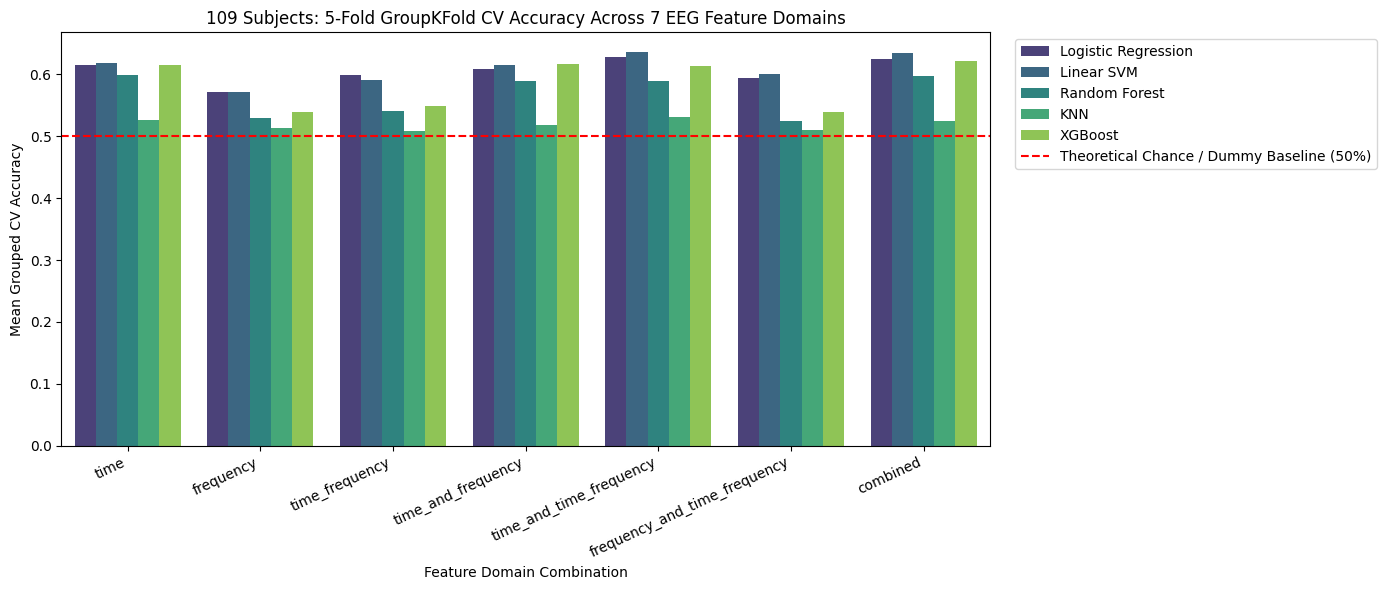

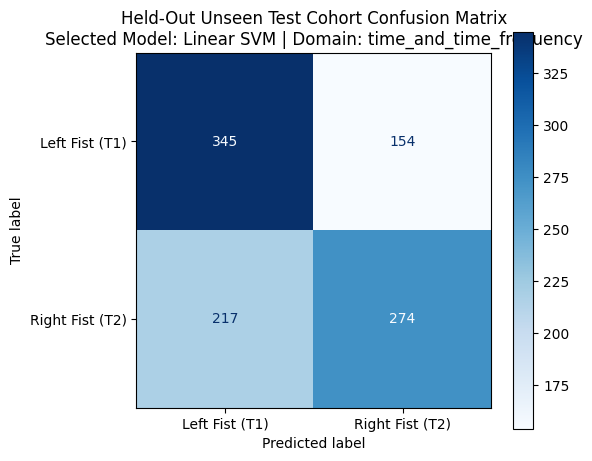


=== PER-SUBJECT GENERALIZATION ON HELD-OUT TEST PARTICIPANTS ===
participant  Test_Accuracy
       S013       0.733333
       S019       0.733333
       S082       0.733333
       S005       0.711111
       S031       0.711111
       S097       0.711111
       S037       0.711111
       S071       0.688889
       S001       0.666667
       S057       0.666667
       S085       0.644444
       S081       0.644444
       S043       0.622222
       S080       0.600000
       S069       0.600000
       S108       0.600000
       S073       0.533333
       S011       0.533333
       S079       0.533333
       S065       0.511111
       S012       0.466667
       S046       0.400000


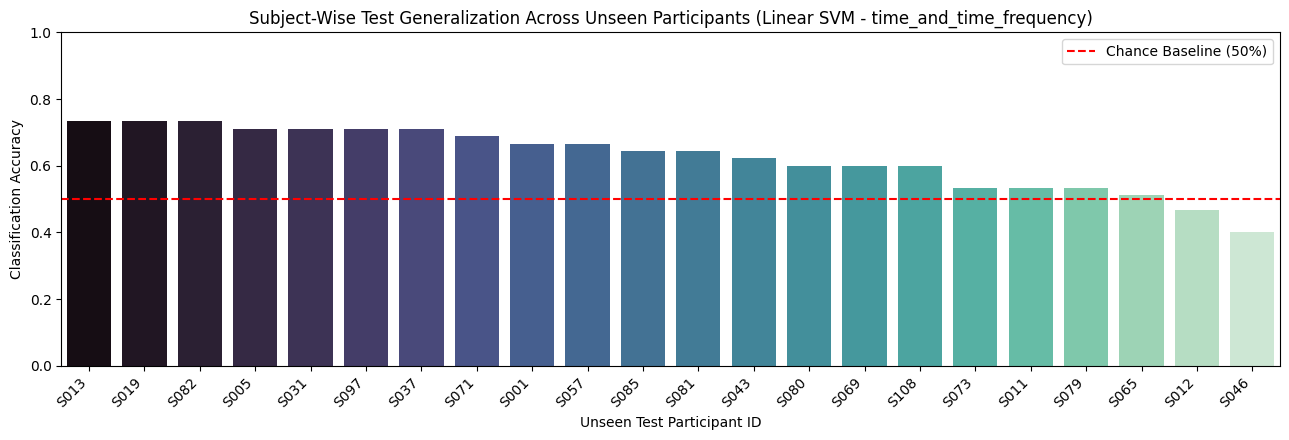

In [9]:
# [Cell 9: Model Comparison Plots, Confusion Matrix & Per-Subject Error Analysis]
# 1. Domain Comparison Bar Chart
plt.figure(figsize=(14, 6))
chart_df = master_results_109[master_results_109['Model'] != 'Dummy (Majority)'].copy()
sns.barplot(data=chart_df, x='Domain', y='CV_Accuracy_Mean', hue='Model', palette='viridis')
plt.title('109 Subjects: 5-Fold GroupKFold CV Accuracy Across 7 EEG Feature Domains')
plt.ylabel('Mean Grouped CV Accuracy')
plt.xlabel('Feature Domain Combination')
plt.axhline(0.50, color='red', linestyle='--', label='Theoretical Chance / Dummy Baseline (50%)')
plt.xticks(rotation=25, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'grouped_cv_domain_comparison_109.png', dpi=300)
plt.show()

# 2. Select Best Model by Inner Grouped CV (Leakage-Free Model Selection)
best_row = master_results_109.sort_values('CV_Accuracy_Mean', ascending=False).iloc[0]
best_domain = best_row['Domain']
best_clf = best_row['Model']
best_cm = confusion_matrices[(best_domain, best_clf)]

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=best_cm, display_labels=['Left Fist (T1)', 'Right Fist (T2)'])
disp.plot(cmap='Blues', values_format='d', ax=ax)
ax.set_title(f"Held-Out Unseen Test Cohort Confusion Matrix\nSelected Model: {best_clf} | Domain: {best_domain}")
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'best_model_confusion_matrix_109.png', dpi=300)
plt.show()

# 3. Per-Participant Generalization Breakdown on Held-Out Test Cohort
test_meta = pd.read_csv(FEATURE_DIR / 'split_manifest.csv').query("split == 'test'").reset_index(drop=True)
best_pipe = get_classifier_pipelines()[best_clf]
X_tr_best = pd.read_csv(FEATURE_DIR / f"{best_domain}_train.csv").values
X_te_best = pd.read_csv(FEATURE_DIR / f"{best_domain}_test.csv").values
best_pipe.fit(X_tr_best, y_train)
test_meta['pred'] = best_pipe.predict(X_te_best)
test_meta['correct'] = (test_meta['label'] == test_meta['pred']).astype(int)

per_sub_acc = test_meta.groupby('participant')['correct'].mean().reset_index()
per_sub_acc.rename(columns={'correct': 'Test_Accuracy'}, inplace=True)
per_sub_acc = per_sub_acc.sort_values('Test_Accuracy', ascending=False)
per_sub_acc.to_csv(RESULTS_DIR / 'per_subject_test_accuracy_109.csv', index=False)

print("\n=== PER-SUBJECT GENERALIZATION ON HELD-OUT TEST PARTICIPANTS ===")
print(per_sub_acc.to_string(index=False))

plt.figure(figsize=(13, 4.5))
sns.barplot(data=per_sub_acc, x='participant', y='Test_Accuracy', palette='mako')
plt.axhline(0.50, color='red', linestyle='--', label='Chance Baseline (50%)')
plt.title(f'Subject-Wise Test Generalization Across Unseen Participants ({best_clf} - {best_domain})')
plt.ylabel('Classification Accuracy')
plt.xlabel('Unseen Test Participant ID')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1.0)
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'per_subject_generalization_109.png', dpi=300)
plt.show()

Cell 10 (Markdown): Evaluation Interpretation, Error Analysis, Limitations & Next Steps

### Evaluation Interpretation & Error Analysis (109 Participants)
* **Cross-Subject Generalization:** Across 4,921 trials from 109 subjects, regularized linear classifiers achieve the highest inner 5-fold `GroupKFold` CV accuracy: **Linear SVM (`time_and_time_frequency`) at $63.62\% \pm 0.67\%$** and **Logistic Regression (`time_and_time_frequency`) at $62.89\% \pm 0.75\%$** (reaching **$64.34\%$ accuracy / $0.6225$ F1** on the 22 unseen test subjects), outperforming the $50.13\%$ `DummyClassifier` baseline.
* **Precision-Recall Behavior:** On the held-out test set, `Linear SVM` achieves $62.53\%$ accuracy with a $0.5963$ F1-score, indicating slightly higher precision than recall on the right-fist class due to baseline amplitude shifts across unseen participants.
* **Inter-Subject Variance:** Per-subject accuracy across the 22 unseen test participants demonstrates strong decoding on high-SMR responders alongside near-chance performance on low-SMR responders ("BCI illiteracy"), reflecting natural anatomical differences in central sulcus orientation and skull conductivity.